# Figure showing the dominant uncertainty by location for each impact

- Main text Figure 2
- Uncertainty partitioning maps separately
- All runs, GWLs 1-4 maps
- Main text Figure 2 with "allyears" specification
- Main text Figure 2 with 1-degree data

In [2]:
import xarray as xr
import xagg as xa
import numpy as np
import pandas as pd
import geopandas as gpd
import os
import re
import glob
import string
import zarr
import warnings
from tqdm.notebook import tqdm

import matplotlib as mpl
from matplotlib import pyplot as plt
from matplotlib import colors as mcolors
from cartopy import crs as ccrs
import cmocean

import distributed

from funcs_support import get_filepaths,get_params,utility_save,utility_print,load_shp
from funcs_readregs import load_dmgfs
from funcs_processing import calc_uncerts
from funcs_plot import plot_map, vals_to_color_triangle, plot_dmgfs

dir_list = get_params()
extra_fonts = {'lato':mpl.font_manager.FontProperties(fname=dir_list['aux']+'fonts/Lato-Regular.ttf'),
 'lato-bold':mpl.font_manager.FontProperties(fname=dir_list['aux']+'fonts/Lato-Bold.ttf')}


In [3]:
params_proc = {'mortality':{'varname':'tassumpoly','geo_typ':'impact-regions','shp_fn':'impact-region','popwght':False},
               'gdppc':{'varname':'tassumpoly','geo_typ':'adm1','shp_fn':'country-fixed','popwght':True},
               'payroll':{'varname':'tasmaxbinF','geo_typ':'adm2-us','shp_fn':'UScounties','popwght':True}}

proc_names = {'mortality':'mort. rate',
              'gdppc':'GDP p.c. growth',
              'payroll':'payroll'}

proc_full_names = {'mortality':'All-cause mortality\n(Carleton et al. 2022)',
                           'gdppc':'GDP per capita growth\n(Burke et al. 2015)',
                           'payroll':'Payroll\n(Behrer et al., 2021)'}


idxs = {'impact-regions':{'hierid':'locid'},
        'adm1':{'CNTRY_NAME':'locid'},
        'adm2-us':{'FIPS':'locid'}}

gwl = 2

reg_x = 0.5 #bbox to find region around location

nsubplt_cols = 2
add_regunc = False

#uncert_typ = '13runs9mods_noMERRA2'
uncert_typ = '13runs9mods'




In [4]:
subplt_locs = {'mortality':{'Tokyo':[35.652832,139.839478],
                            'Kolkata':[22.572645, 88.363892],
              'Dallas':[32.779167, -96.808891],
              'Cape Town':[-33.918861,18.423300]},
               'gdppc':{'Germany':[50.555809, 9.680845],
                            'India':[22.572645, 83.363892],
              'USA':[32.779167, -96.808891],
              'South Africa':[-33.918861,18.423300]},
               'payroll':{'Seattle':[47.608013, -122.335167],
                            'New York':[40.730610,-73.935242],
              'Dallas':[32.779167, -96.808891],
              'Chicago':[41.881832,-87.623177]}}


In [5]:
def load_impacts(proc,uncert_typ,subplot_regs_all,return_maxgwl = False,return_crossfits=False,load=True,res='025deg',byyr=False):
    '''
    NOTE: MAX_GWL IS HARDCODED HERE
    '''
    
    # Load impacts projections
    if return_crossfits:
        fns = np.sort(glob.glob(f'{dir_list['proc']}impact_projs/{proc}/d{proc}-cross_agg_*.zarr'))
    else:
        if res == '025deg':
            fns = np.sort(glob.glob(f'{dir_list['proc']}impact_projs/{proc}/d{proc}_agg_*.zarr'))
        else:
            if byyr:
                fns = np.sort(glob.glob(f'{dir_list['proc']}impact_projs/{proc}/d{proc}_agg-1deg_*ALLTIMEFRAMES*.zarr'))
            else:
                fns = np.sort(glob.glob(f'{dir_list['proc']}impact_projs/{proc}/d{proc}_agg-1deg_*.zarr'))
    def load_impact(fn):
        ds_tmp = xr.open_zarr(fn,consolidated=False)
        ds_tmp = ds_tmp.set_coords('locid') # Should be coordinate, instead of concatenated variable
        ds_tmp = ds_tmp.assign_coords({'model':(('idv'),[re.split(r'\_',re.split(r'\/',fn)[-1])[2]]*ds_tmp.sizes['idv'])})
    
        ds_tmp['exprun'] = ds_tmp['experiment']+ds_tmp['run']
        ds_tmp = ds_tmp.reset_index('idv')
        ds_tmp = ds_tmp.set_index(idv = ['model','exprun'])
        return ds_tmp
    
    with warnings.catch_warnings():
        # Silence zarr warnings related to the /.done flags used
        warnings.filterwarnings('ignore')
        dss = xr.concat([load_impact(fn) for fn in fns],
                    dim='idv',join='outer')
    
    dss = dss.set_index({'poly_idx':'locid'}).rename({'poly_idx':'locid'})

    if return_maxgwl:
        return dss.maxgwl
    
    # Figure out how many BCD-ME members reach a given GWL
    gwl_counter = dss.maxgwl.load().reset_index('idv').groupby(['model','maxgwl']).count()
    gwl_counter = gwl_counter.sel(maxgwl = gwl_counter.maxgwl.values[::-1]).cumsum('maxgwl')
    #print(gwl_counter)
    
    dss_tmp = dss.copy()
    
    if 'noMERRA2' in uncert_typ:
        dss_tmp = dss_tmp.sel(proj_base = [pb for pb in dss_tmp.proj_base.values if pb != 'MERRA2'])
    
    if re.search(r'[0-9].*runs[0-9].*mods',uncert_typ):
        max_gwl = 3
        nruns = int(re.split('runs',uncert_typ)[0])
        
        gwlmods = gwl_counter.sel(maxgwl=max_gwl)
        proc_mods = gwlmods.isel(model = gwlmods>=nruns).model.values
        
        dss_tmp = dss_tmp.isel(idv = dss.maxgwl>=max_gwl).groupby('model').map(lambda x: x.isel(idv=slice(0, nruns)))
        dss_tmp = dss_tmp.isel(idv=[m in proc_mods for m in dss_tmp.model.values]).chunk({'idv':-1})

    for v in ['experiment','run']:
        dss_tmp[v] = dss_tmp[v].astype(object)
    dss_tmp = dss_tmp.unstack('idv')['d'+proc]
    dss_tmp = dss_tmp.chunk({'model':-1,'exprun':-1})
    
    # Get mean over all needed locations
    dss_tmp = dss_tmp.sel(locid = subplt_regs_all.locid.values)
    if load:
        dss_tmp = dss_tmp.load()
    return dss_tmp


def stacked_lineplot(plot_data,ax = None,
                add_legend = False,
                 plot_type = 'bar', #'bar' or 'line'
                 xdim = 'gwl',
                uncert_colors = {'uncmod':'tab:blue',
                                 'uncsce':'green',
                                 'uncint':'tab:orange',
                                 'uncobs':'tab:green',
                                 'uncreg':'lightgrey'},
                unc_source_names = {'uncint':'internal var.',
                                    'uncmod':'model unc.',
                                    'uncobs':'observational unc.',
                                    'uncreg':'regression unc.',
                                    'uncsce':'scenario unc.'},
                    var_order = ['uncobs','uncint','uncmod','uncsce','uncreg']
                    ):

    if ax is None:
        ax = plt.subplot()

    varlist = [var for var in plot_data if var in uncert_colors]
    varlist = [var for var in var_order if var in varlist]

    # Plot mean change line
    ax.plot(plot_data.gwl.values, plot_data['meanl'], color="k", lw=2, label=r'Mean $\Delta$ mort.')

    # Start from the mean line
    lower = plot_data['meanl'].values.copy()
    upper = plot_data['meanl'].values.copy()
    
    # Add each uncertainty source
    for unc in varlist:
        # half goes above, half below
        mag = np.sqrt(plot_data[unc]) / 2
        ax.fill_between(plot_data[unc].gwl.values, 
                        lower, lower-mag,
            color = uncert_colors[unc],
            label=unc
        )
        ax.fill_between(plot_data[unc].gwl.values, 
                        upper, upper+mag,
            color = uncert_colors[unc],
            label=unc
        )
    
        lower -= mag
        upper += mag

    if add_legend:
        ax.legend(bbox_to_anchor=(1,1))

    ax.set_xlabel(r'GWL [$^\circ$C]')
    #ax.set_ylabel('Frac. contribution to total variance')

    return ax

def stacked_plot(plot_data,ax = None,
                add_legend = False,
                 plot_type = 'bar', #'bar' or 'line'
                 xdim = 'gwl',
                uncert_colors = {'uncmod':'tab:blue',
                                 'uncsce':'green',
                                 'uncint':'tab:red',
                                 'uncobs':'tab:green',
                                 'uncreg':'lightgrey'},
                unc_source_names = {'uncint':'internal var.',
                                    'uncmod':'model unc.',
                                    'uncobs':'observational unc.',
                                    'uncreg':'regression unc.',
                                    'uncsce':'scenario unc.'}):

    if ax is None:
        ax = plt.subplot()
    
    varlist = [var for var in plot_data if var in uncert_colors]
    
    bottom = np.zeros(plot_data.sizes[xdim])
    for var in varlist:
        plot_values = plot_data[var]

        if plot_type == 'bar':
            p = ax.bar(np.arange(0,plot_data.sizes[xdim]),
                       plot_values, label=unc_source_names[var],
                       color = uncert_colors[var],
                       bottom=bottom)
        elif plot_type == 'line':
            ax.fill_between(plot_values[xdim],
                            bottom,
                            bottom + plot_values,
                            color = uncert_colors[var],
                            label = unc_source_names[var])
        bottom += plot_values

    
    if plot_type == 'bar':
        ax.set_xticks(np.arange(0,plot_data.sizes[xdim]),
                      plot_values.gwl.values)
    elif plot_type == 'line':
        ax.set_xlim([plot_data[xdim].values[0],plot_data[xdim].values[-1]])

    

    if add_legend:
        ax.legend(bbox_to_anchor=(1,1))

    ax.set_xlabel(r'GWL [$^\circ$C]')
    ax.set_ylabel('Frac. contribution to total variance')

    return ax

## Main text figure

Procesing mortality...


/glade/derecho/scratch/schwarzwald/tmp/ipykernel_90721/1674877682.py:59: DeprecationWarning: Deleting a single level of a MultiIndex is deprecated. Previously, this deleted all levels of a MultiIndex. Please also drop the following variables: {'idv'} to avoid an error in the future.
  dss_tmp[v] = dss_tmp[v].astype(object)
/glade/derecho/scratch/schwarzwald/tmp/ipykernel_90721/1674877682.py:59: DeprecationWarning: Deleting a single level of a MultiIndex is deprecated. Previously, this deleted all levels of a MultiIndex. Please also drop the following variables: {'idv'} to avoid an error in the future.
  dss_tmp[v] = dss_tmp[v].astype(object)
/glade/derecho/scratch/schwarzwald/tmp/ipykernel_90721/836820758.py:173: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dim

Procesing gdppc...


/glade/derecho/scratch/schwarzwald/tmp/ipykernel_90721/1674877682.py:59: DeprecationWarning: Deleting a single level of a MultiIndex is deprecated. Previously, this deleted all levels of a MultiIndex. Please also drop the following variables: {'idv'} to avoid an error in the future.
  dss_tmp[v] = dss_tmp[v].astype(object)
/glade/derecho/scratch/schwarzwald/tmp/ipykernel_90721/1674877682.py:59: DeprecationWarning: Deleting a single level of a MultiIndex is deprecated. Previously, this deleted all levels of a MultiIndex. Please also drop the following variables: {'idv'} to avoid an error in the future.
  dss_tmp[v] = dss_tmp[v].astype(object)
/glade/derecho/scratch/schwarzwald/tmp/ipykernel_90721/836820758.py:173: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dim

Procesing payroll...


/glade/derecho/scratch/schwarzwald/tmp/ipykernel_90721/1674877682.py:59: DeprecationWarning: Deleting a single level of a MultiIndex is deprecated. Previously, this deleted all levels of a MultiIndex. Please also drop the following variables: {'idv'} to avoid an error in the future.
  dss_tmp[v] = dss_tmp[v].astype(object)
/glade/derecho/scratch/schwarzwald/tmp/ipykernel_90721/1674877682.py:59: DeprecationWarning: Deleting a single level of a MultiIndex is deprecated. Previously, this deleted all levels of a MultiIndex. Please also drop the following variables: {'idv'} to avoid an error in the future.
  dss_tmp[v] = dss_tmp[v].astype(object)
/glade/derecho/scratch/schwarzwald/tmp/ipykernel_90721/836820758.py:173: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dim

/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/Figure3.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/Figure3.png saved!


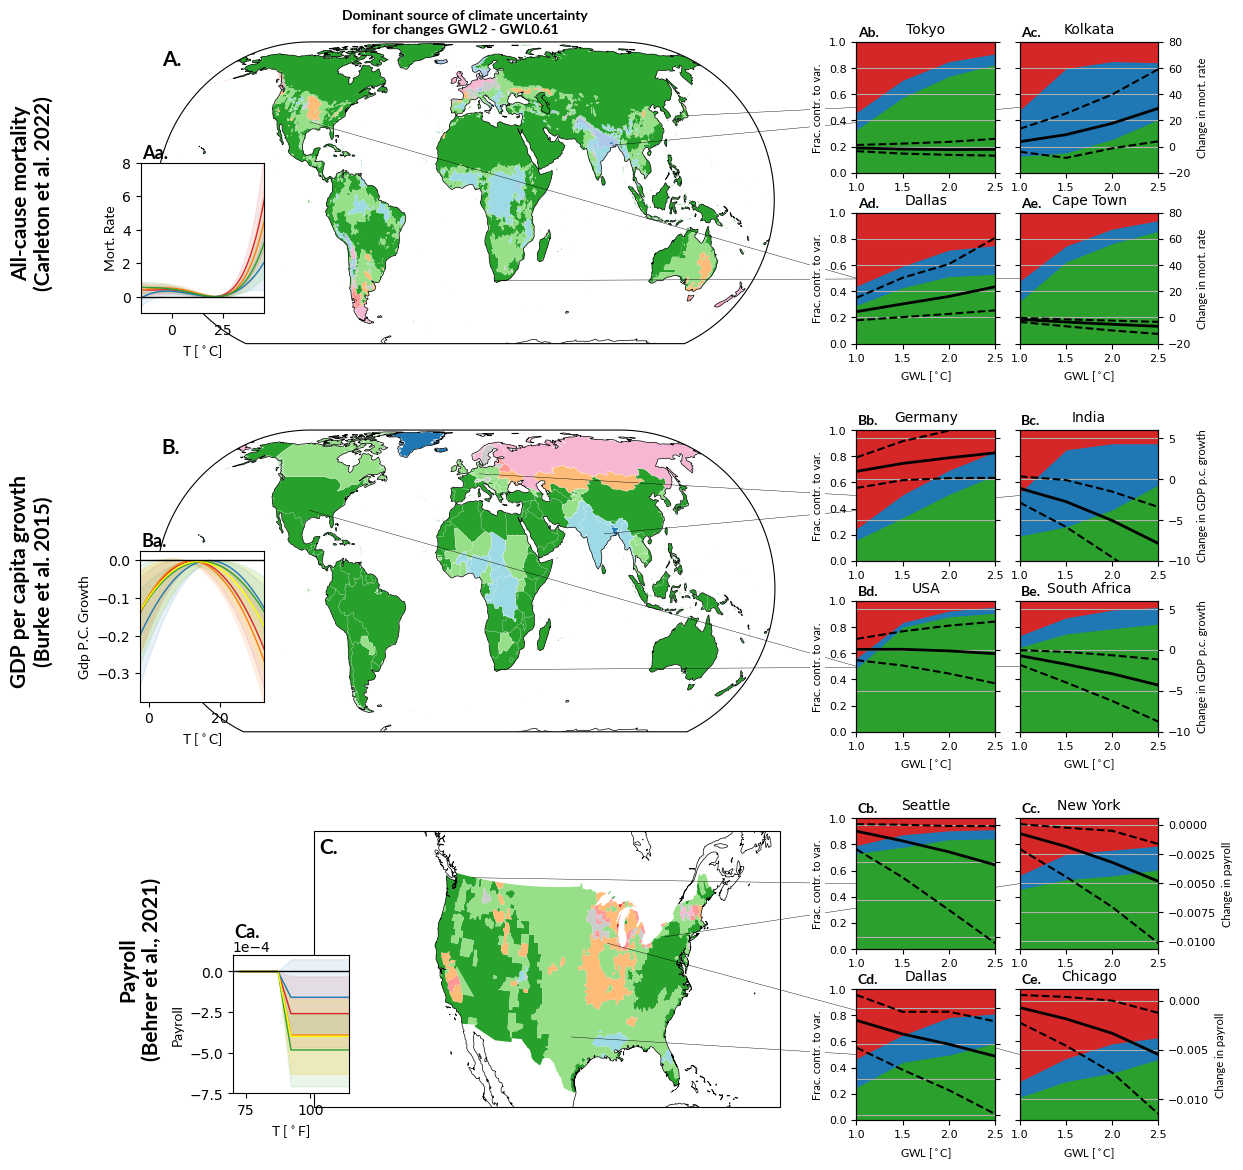

In [7]:
save_fig = True
output_fn = dir_list['figs']+'Figure3'

gwl = 2
uncert_typ = {'mortality':'13runs8mods',
              'gdppc':'13runs8mods',
              'payroll':'10runs7mods'}
#if 'noMERRA2' not in uncert_typ:
#    output_fn = output_fn+'_wMERRA2'

imp_params = {'mortality':{'timeframe':'1980-2010','obstreat':'sep','resolution':'025deg','spec':'pooled','indflag':'noInd'},
              'gdppc':{'timeframe':'1980-2010','obstreat':'sep','resolution':'025deg'},
              'payroll':{'timeframe':'1986-2008','obstreat':'sep','resolution':'025deg','weighting':'pop'}}

projs = {'mortality':ccrs.EckertIV(),
         'gdppc':ccrs.EckertIV(),
         'payroll':ccrs.AlbersEqualArea(central_longitude=-100,central_latitude=35)}


fig = plt.figure(figsize=(13,14))

gs = plt.GridSpec(nrows=2*len(params_proc) + (len(params_proc) -1),
                  ncols= 4 + nsubplt_cols + 1,
                  width_ratios=[*([1]*4),0.2,*([1]*nsubplt_cols)],
                  height_ratios = [1,1,*([0.05,1,1]*(len(params_proc)-1))],
                  hspace = 0.4,wspace=0.2)

for row_idx,proc in enumerate(params_proc):
    print(f'Procesing {proc}...')
    #-------------------------
    # Load plot data ---------
    #-------------------------
    
    # Load partitioned uncertainty
    fn = f'{dir_list['proc']}uncert_parts/uncert_parts_{proc}.zarr'
    uncerts = xr.open_zarr(fn).load()
    uncerts = uncerts.set_index(poly_idx = 'locid').rename({'poly_idx':'locid'})

    # Select desired specification
    uncerts = uncerts.sel(imp_params[proc])

    # Load shapefile
    gdf = load_shp(proc)

    # Get regions for subplot
    # All regions that touch +/- reg_x of the central coordinate
    subplt_regs = {name:gdf.cx[(lon-reg_x):(lon+reg_x),(lat-reg_x):(lat+reg_x)]
                    for name,(lat,lon) in subplt_locs[proc].items()}
    subplt_regs_all = pd.concat([lc for name,lc in subplt_regs.items()])

    # Load raw change in impacts
    dss_tmp = load_impacts(proc,uncert_typ[proc],subplt_regs_all)
    # Select desired specification
    dss_tmp = dss_tmp.sel(imp_params[proc])
    
    #-------------------------
    # Map panel --------------
    #-------------------------
    if params_proc[proc]['geo_typ'] == 'adm2-us':
        # Only use part of the horizontal grid spec for the smaller counties map
        ax_map = fig.add_subplot(gs[(row_idx*2 + row_idx):((row_idx+1)*2 + row_idx),1:4],projection=projs[proc])
    else: 
        ax_map = fig.add_subplot(gs[(row_idx*2 + row_idx):((row_idx+1)*2 + row_idx),0:4],projection=projs[proc])

    
    plot_data = (uncerts.
                 sel(typ='norm',gwl=gwl,sample=uncert_typ[proc]).
                 to_dataarray().to_dataset(name='relvar'))
    # Turn scenario, model, internal into color triangle colors
    plot_data['colors'] = xr.DataArray(data=vals_to_color_triangle(plot_data['relvar'],
                                                                dim='variable',
                                                                col_names = {'r':'uncint',
                                                                             'g':'uncobs',
                                                                             'b':'uncmod'}),
                                            dims=['locid'])
    
    # Add to geodataframe
    plot_data = pd.merge(gdf,
                      (plot_data[['colors','locid']].to_dataframe().reset_index()),
                      on='locid')

    # Dissolve into single polygons by color to reduce pdf file size
    plot_data = plot_data.dissolve(by='colors').reset_index()
    
    # Plot
    plot_data.plot(color=plot_data.colors,ax=ax_map,transform=ccrs.PlateCarree())
    # Plot national boundaries at least
    if proc == 'gdppc':
        gdf.plot(ax=ax_map,facecolor='none',edgecolor='w',linewidth=0.1,transform=ccrs.PlateCarree())

    # Make the payroll figure span a little wider, so the aspect ratio fits better
    # with the global maps
    if proc == 'payroll':
        ax_map.set_extent((-140, -64, 23.7, 50.6),
                  crs = ccrs.PlateCarree())
    
    # Annotations
    ax_map.coastlines(linewidth=0.5)
    ax_map.annotate(string.ascii_uppercase[row_idx]+'.',(0.01,0.975),xycoords = 'axes fraction',
                fontweight='bold',fontsize=15,va='top',font=extra_fonts['lato-bold'])
    
    if row_idx == 0:
        ax_map.set_title('Dominant source of climate uncertainty\nfor changes GWL'+str(gwl)+' - GWL0.61',
                         fontsize=20,font=extra_fonts['lato-bold'])

    # Row labels
    if proc == 'payroll':
        row_ann_pos = (-0.375,0.5)
    else:
        row_ann_pos = (-0.2,0.5)
    ax_map.annotate(proc_full_names[proc],
                    row_ann_pos,xycoords = 'axes fraction',
                    fontweight='bold',fontsize=15,va='center',ha='center',
                    rotation=90,font=extra_fonts['lato-bold'])
    
    #-------------------------
    # Damage function panels -
    #-------------------------
    if proc == 'payroll':
        inset_coords = (-0.175,0.05,0.25,0.5)
    else:
        inset_coords = (-0.025,0.1,0.2,0.5)
    ax_dmgf = ax_map.inset_axes(inset_coords)

    dmgfs = load_dmgfs(proc)
    if 'noMERRA2' in uncert_typ[proc]:
        dmgfs = dmgfs.sel(proj_base = [pb for pb in dmgfs.proj_base.values if pb != 'MERRA2'])
    
    ax_dmgf = plot_dmgfs(dmgfs,proc,simple=True,ax=ax_dmgf)

    # Subplot lettering
    if proc == 'payroll':
        ax_dmgf.annotate(string.ascii_uppercase[row_idx]+'a.',(0.01,1.11),xycoords = 'axes fraction',
                fontweight='bold',fontsize=13,va='bottom',font=extra_fonts['lato-bold'])
    else:
        ax_dmgf.annotate(string.ascii_uppercase[row_idx]+'a.',(0.01,1.01),xycoords = 'axes fraction',
                fontweight='bold',fontsize=13,va='bottom',font=extra_fonts['lato-bold'])

    if proc == 'payroll':
        ax_dmgf.set_xlabel(r'T [$^\circ$F]',font=extra_fonts['lato'])
    else:
        ax_dmgf.set_xlabel(r'T [$^\circ$C]',font=extra_fonts['lato'])
    ax_dmgf.set_ylabel(proc_names[proc].title(),font=extra_fonts['lato'])

    if proc == 'payroll':
        ax_dmgf.ticklabel_format(axis='y',style='sci',scilimits = (0,0))
                
    #-------------------------
    # Reference varpart panels 
    #-------------------------
    # --- Right-hand subplot slots ---
    axes = [fig.add_subplot(gs[row_idx*2 + (subplt_idx // nsubplt_cols) + row_idx,
                               4 + 1 + (subplt_idx % nsubplt_cols)],
                            zorder = 2)
            for subplt_idx in range(len(subplt_locs[proc]))]
    
    # --- Helper: midpoint of subplot edge ---
    def edge_point(ax):
        bb = ax.get_position()  # in figure fraction
        return (bb.x0, (bb.y0 + bb.y1) / 2)
        #return (bb.x0, bb.y1)
        
    # --- Loop over explicitly assigned locations ---
    bbox_params = {'facecolor':'w','edgecolor':'none','pad':1.5}
    for plt_idx, (name, (lat, lon)), ax in zip(range(len(subplt_locs[proc])), subplt_locs[proc].items(), axes):
        # Title + dummy plot
        ax.set_title(name,
                     bbox = bbox_params,
                     zorder=5,
                     fontsize=10)
        # Get regions around the desired location
        regs_tmp = gdf.cx[(lon-reg_x):(lon+reg_x),(lat-reg_x):(lat+reg_x)]
        plot_data = xr.merge([uncerts.sel(locid=subplt_regs[name].locid.values,
                                          sample = uncert_typ[proc]),
                              dss_tmp.sel(locid = subplt_regs[name].locid.values)],
                             compat = 'override')
        plot_data = plot_data.sel(gwl=slice(1,2.5))
        plot_data = plot_data.mean('locid')
    
        if add_regunc:
            plot_data_tmp = plot_data.sel(typ='norm')[['uncreg','uncobs','uncmod','uncint']]
        else:
            plot_data_tmp = plot_data.sel(typ='norm')[['uncobs','uncmod','uncint']]
        ax = stacked_plot(plot_data_tmp/plot_data_tmp.to_dataarray().sum('variable'),
                     ax=ax,add_legend=False,
                         plot_type='line')
        ax.set_ylim([0,1])
    
        ax2 = ax.twinx()
        # Plot mean change + 95% IQR
        plot_data[f'd{proc}'].mean(['proj_base','model','exprun']).plot(color='k',linewidth=2)
        #rng_clim = np.sqrt(plot_data.sel(typ='raw')[['uncobs','uncmod','uncint']].to_dataarray().sum('variable'))
        #rng_all = np.sqrt(plot_data.sel(typ='raw')[['uncreg','uncobs','uncmod','uncint']].to_dataarray().sum('variable'))
    
        for q in [0.025,0.975]:
            plot_data[f'd{proc}'].quantile(q,['proj_base','model','exprun']).plot(color='k',linestyle='--')
        #(plot_data['meanl']+rng_all).plot(color='k',linestyle=':')
        #(plot_data['meanl']-rng_all).plot(color='k',linestyle=':')

        if proc == 'mortality':
            ax2.set_ylim([-20,80])
        elif proc == 'gdppc':
            ax2.set_ylim([-10,6])
        ax2.grid()
    
        # Leftmost subplots get left yaxis label
        if plt_idx % nsubplt_cols == 0:
            ax.set_ylabel('Frac. contr. to var.',fontsize=8,bbox=bbox_params,
                          font=extra_fonts['lato'])
        else:
            ax.set_ylabel('')
    
        # Rightmost subplots get right yaxis label
        if (plt_idx + 1) % nsubplt_cols == 0:
            ax2.set_ylabel(f'Change in {proc_names[proc]}',fontsize=8,font=extra_fonts['lato'])
        else:
            ax2.set_ylabel('')
    
        # Subplots to the right of the first column get no left yaxis labels
        if plt_idx % nsubplt_cols > 0:
            ax.set_yticklabels([])
        # Subplots to the left of the last column get no right yaxis labels
        if (plt_idx + 1) % nsubplt_cols > 0:
            ax2.set_yticklabels([])
    
        # Xlabel only on bottom row
        if plt_idx >= nsubplt_cols: 
            ax.set_xlabel(r'GWL [$^\circ$C]',fontsize=8,font=extra_fonts['lato'])
        else:
            ax.set_xlabel('')
        ax2.set_xlabel('')
        ax2.set_title('')
    
        ax.tick_params(axis='both', labelsize=8)
        ax2.tick_params(axis='both', labelsize=8)
    
        # Sublot lettering
        ax.annotate(string.ascii_uppercase[row_idx]+string.ascii_lowercase[plt_idx+1]+'.',
                    (0.01,1.025),xycoords = 'axes fraction',
                    fontweight='bold',fontsize=10,va='bottom',font=extra_fonts['lato-bold'])
    
    
        # Map point → figure coordinates
        lon_proj,lat_proj = ax_map.projection.transform_point(lon, lat, ccrs.PlateCarree())
        disp = ax_map.transData.transform((lon_proj, lat_proj))  # PlateCarree input
        map_fig = fig.transFigure.inverted().transform(disp)
    
        # Subplot edge anchor
        anchor_fig = edge_point(ax)
    
        # Draw leader line
        line = plt.Line2D(
            [map_fig[0], anchor_fig[0]],
            [map_fig[1], anchor_fig[1]],
            transform=fig.transFigure,
            color="k",
            lw=0.3,
            zorder=1,
        )
        fig.lines.append(line)


if save_fig:
    utility_print(output_fn)



## Map figures by themselves

/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/uncert_part_map_dmortality_GWL2_eaproj.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/uncert_part_map_dmortality_GWL2_eaproj.png saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/uncert_part_map_dgdppc_GWL2_eaproj.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/uncert_part_map_dgdppc_GWL2_eaproj.png saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/uncert_part_map_dpayroll_GWL2_eaproj.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/uncert_part_map_dpayroll_GWL2_eaproj.png saved!


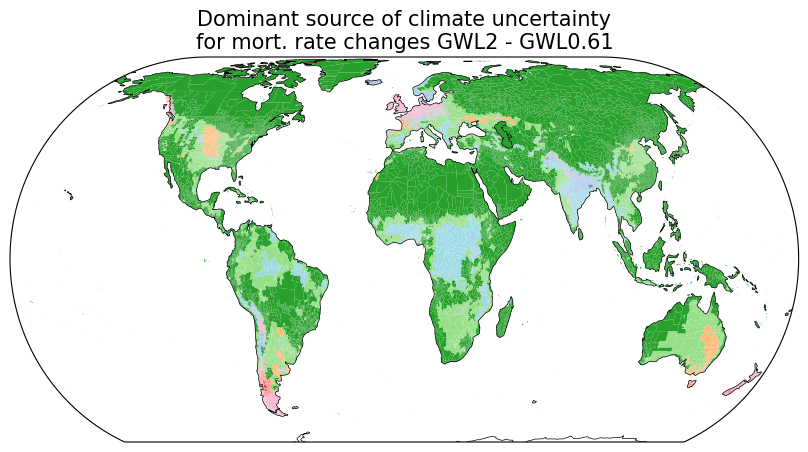

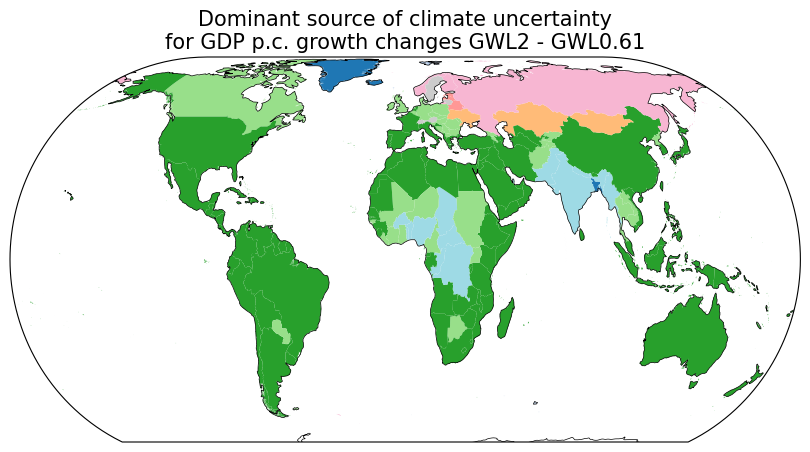

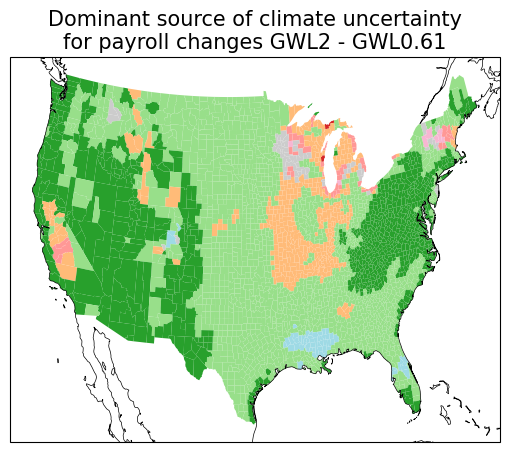

In [22]:
save_fig = True

imp_params = {'mortality':{'timeframe':'1980-2010','obstreat':'sep','resolution':'025deg','spec':'pooled','indflag':'noInd'},
              'gdppc':{'timeframe':'1980-2010','obstreat':'sep','resolution':'025deg'},
              'payroll':{'timeframe':'1986-2008','obstreat':'sep','resolution':'025deg','weighting':'pop'}}

projs = {'mortality':ccrs.EckertIV(),
         'gdppc':ccrs.EckertIV(),
         'payroll':ccrs.AlbersEqualArea(central_longitude=-100,central_latitude=35)}

# Now, just the map 
for proc in ['mortality','gdppc','payroll']:
    fig = plt.figure(figsize=(12,5))

    proj = projs[proc]
    if proj != ccrs.PlateCarree():
        projstr = '_eaproj'
    #-------------------------
    # Load plot data ---------
    #-------------------------
    
    # Load partitioned uncertainty
    fn = f'{dir_list['proc']}uncert_parts/uncert_parts_{proc}.zarr'
    uncerts = xr.open_zarr(fn).load()
    uncerts = uncerts.set_index(poly_idx = 'locid').rename({'poly_idx':'locid'})

    # Select desired specification
    uncerts = uncerts.sel(imp_params[proc])

    # Load shapefile
    gdf = load_shp(proc)

    # Get regions for subplot
    # All regions that touch +/- reg_x of the central coordinate
    subplt_regs = {name:gdf.cx[(lon-reg_x):(lon+reg_x),(lat-reg_x):(lat+reg_x)]
                    for name,(lat,lon) in subplt_locs[proc].items()}
    subplt_regs_all = pd.concat([lc for name,lc in subplt_regs.items()])

    #-------------------------
    # Map panel --------------
    #-------------------------
    ax_map = plt.subplot(projection=proj)
   
    plot_data = (uncerts.
                 sel(typ='norm',gwl=gwl,sample=uncert_typ[proc]).
                 to_dataarray().to_dataset(name='relvar'))
    # Turn scenario, model, internal into color triangle colors
    plot_data['colors'] = xr.DataArray(data=vals_to_color_triangle(plot_data['relvar'],
                                                                dim='variable',
                                                                col_names = {'r':'uncint',
                                                                             'g':'uncobs',
                                                                             'b':'uncmod'}),
                                            dims=['locid'])
    
    # Add to geodataframe
    plot_data = pd.merge(gdf,
                      (plot_data[['colors','locid']].to_dataframe().reset_index()),
                      on='locid')
    
    # Plot
    plot_data.plot(color=plot_data.colors,ax=ax_map,transform=ccrs.PlateCarree())
    
    # Annotations
    ax_map.coastlines(linewidth=0.5)
    #ax_map.annotate(string.ascii_uppercase[row_idx]+'.',(0.01,0.975),xycoords = 'axes fraction',
    #            fontweight='bold',fontsize=15,va='top',font=extra_fonts['lato-bold'])
    

    ax_map.set_title('Dominant source of climate uncertainty\nfor '+proc_names[proc]+' changes GWL'+str(gwl)+' - GWL0.61',
                         fontsize=15)#font=extra_fonts['lato-bold'])

    if save_fig:
        utility_print(f'{dir_list['figs']}extra_figs/uncert_part_map_d{proc}_GWL{str(gwl)}{projstr}')

## Location subplots by themselves

/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/pyogrio/raw.py:200: RuntimeWarning: /glade/u/home/schwarzwald/projects/impact_uncertainty/aux_data/geo_data/impact-region.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(
/glade/derecho/scratch/schwarzwald/tmp/ipykernel_41653/1674877682.py:59: DeprecationWarning: Deleting a single level of a MultiIndex is deprecated. Previously, this deleted all levels of a MultiIndex. Please also drop the following variables: {'idv'} to avoid an error in the future.
  dss_tmp[v] = dss_tmp[v].astype(object)
/glade/derecho/scratch/schwarzwald/tmp/ipykernel_41653/1674877682.py:59: DeprecationWarning: Deleting a single level of a MultiIndex is deprecated. Previously, this deleted all levels of a MultiIndex. Please also drop the following variables: {'idv'} to avoid an error in the future.
  dss_tmp[v] = dss_

/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/uncertpart_singleloc_mortality_Chicago.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/uncertpart_singleloc_mortality_Chicago.png saved!


/glade/derecho/scratch/schwarzwald/tmp/ipykernel_41653/865069419.py:76: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'model' ('model',) The recommendation is to set join explicitly for this case.
  plot_data = xr.merge([uncerts.sel(locid=subplt_regs[name].locid.values,


/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/uncertpart_singleloc_mortality_Kolkata.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/uncertpart_singleloc_mortality_Kolkata.png saved!


/glade/derecho/scratch/schwarzwald/tmp/ipykernel_41653/865069419.py:76: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'model' ('model',) The recommendation is to set join explicitly for this case.
  plot_data = xr.merge([uncerts.sel(locid=subplt_regs[name].locid.values,


/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/uncertpart_singleloc_mortality_Dallas.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/uncertpart_singleloc_mortality_Dallas.png saved!


/glade/derecho/scratch/schwarzwald/tmp/ipykernel_41653/865069419.py:76: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'model' ('model',) The recommendation is to set join explicitly for this case.
  plot_data = xr.merge([uncerts.sel(locid=subplt_regs[name].locid.values,


/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/uncertpart_singleloc_mortality_Cape Town.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/uncertpart_singleloc_mortality_Cape Town.png saved!


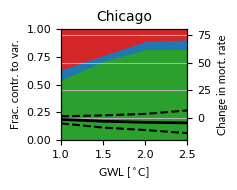

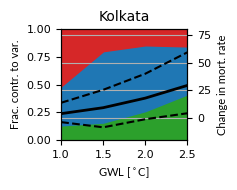

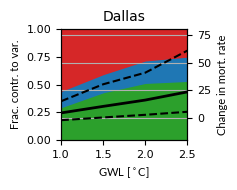

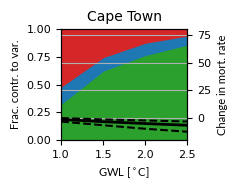

In [23]:
subplt_locs_tmp = {'mortality': {'Chicago': [41.88, -87.63],
  'Kolkata': [22.572645, 88.363892],
  'Dallas': [32.779167, -96.808891],
  'Cape Town': [-33.918861, 18.4233]}}

uncert_typ = {'mortality':'13runs8mods',
              'gdppc':'13runs8mods',
              'payroll':'10runs7mods'}

save_fig = True


imp_params = {'mortality':{'timeframe':'1980-2010','obstreat':'sep','resolution':'025deg','spec':'pooled','indflag':'noInd'},
              'gdppc':{'timeframe':'1980-2010','obstreat':'sep','resolution':'025deg'},
              'payroll':{'timeframe':'1986-2008','obstreat':'sep','resolution':'025deg','weighting':'pop'}}


#-------------------------
# Reference varpart panels 
#-------------------------    
# --- Loop over explicitly assigned locations ---
bbox_params = {'facecolor':'w','edgecolor':'none','pad':1.5}
for proc in subplt_locs_tmp:
    #-------------------------
    # Load plot data ---------
    #-------------------------    
    # Load partitioned uncertainty
    fn = f'{dir_list['proc']}uncert_parts/uncert_parts_{proc}.zarr'
    uncerts = xr.open_zarr(fn).load()
    uncerts = uncerts.set_index(poly_idx = 'locid').rename({'poly_idx':'locid'})

    # Select desired specification
    uncerts = uncerts.sel(imp_params[proc])

    # Load shapefile
    gdf = gpd.read_file(f'{dir_list['aux']}geo_data/{params_proc[proc]['shp_fn']}.shp')
    gdf['geometry'] = gdf.make_valid()

    if params_proc[proc]['geo_typ'] == 'impact-regions':
        # Remove Antarctica
        gdf = gdf.query('ISO != "ATA"')
    elif params_proc[proc]['geo_typ'] == 'adm1':
        gdf = gdf.query('CNTRY_NAME != "Antarctica"')
    elif params_proc[proc]['geo_typ'] == 'adm2-us':
        # Remove Alaska and Hawaii
        gdf = gdf.iloc[[sn not in ['Alaska','Hawaii'] for sn in gdf.STATE_NAME.values]]
    
    # Name merging dimension 'locid'
    gdf = gdf.rename(idxs[params_proc[proc]['geo_typ']],axis=1)

    # Get regions for subplot
    # All regions that touch +/- reg_x of the central coordinate
    subplt_regs = {name:gdf.cx[(lon-reg_x):(lon+reg_x),(lat-reg_x):(lat+reg_x)]
                    for name,(lat,lon) in subplt_locs_tmp[proc].items()}
    subplt_regs_all = pd.concat([lc for name,lc in subplt_regs.items()])
    
    # Load raw change in impacts
    dss_tmp = load_impacts(proc,uncert_typ[proc],subplt_regs_all,load=False)
    # Select desired specification
    dss_tmp = dss_tmp.sel(imp_params[proc])

    #-------------------------
    # Plot ---------
    #-------------------------
    for plt_idx, (name, (lat, lon)) in zip(range(len(subplt_locs_tmp[proc])), subplt_locs_tmp[proc].items()):
        output_fn = f'{dir_list['figs']}extra_figs/uncertpart_singleloc_{proc}_{name}'
        fig = plt.figure(figsize=(2.5,2))
        ax = plt.subplot()
        # Title + dummy plot
        ax.set_title(name,
                     bbox = bbox_params,
                     zorder=5,
                     fontsize=10)
        # Get regions around the desired location
        regs_tmp = gdf.cx[(lon-reg_x):(lon+reg_x),(lat-reg_x):(lat+reg_x)]
        plot_data = xr.merge([uncerts.sel(locid=subplt_regs[name].locid.values,
                                          sample = uncert_typ[proc]),
                              dss_tmp.sel(locid = subplt_regs[name].locid.values)],
                             compat = 'override')
        plot_data = plot_data.sel(gwl=slice(1,2.5))
        plot_data = plot_data.mean('locid')
    
        if add_regunc:
            plot_data_tmp = plot_data.sel(typ='norm')[['uncreg','uncobs','uncmod','uncint']]
        else:
            plot_data_tmp = plot_data.sel(typ='norm')[['uncobs','uncmod','uncint']]
        ax = stacked_plot(plot_data_tmp/plot_data_tmp.to_dataarray().sum('variable'),
                     ax=ax,add_legend=False,
                         plot_type='line')
        ax.set_ylim([0,1])
    
        ax2 = ax.twinx()
        # Plot mean change + 95% IQR
        plot_data[f'd{proc}'].mean(['proj_base','model','exprun']).plot(color='k',linewidth=2)
        #rng_clim = np.sqrt(plot_data.sel(typ='raw')[['uncobs','uncmod','uncint']].to_dataarray().sum('variable'))
        #rng_all = np.sqrt(plot_data.sel(typ='raw')[['uncreg','uncobs','uncmod','uncint']].to_dataarray().sum('variable'))
    
        for q in [0.025,0.975]:
            plot_data[f'd{proc}'].quantile(q,['proj_base','model','exprun']).plot(color='k',linestyle='--')
        #(plot_data['meanl']+rng_all).plot(color='k',linestyle=':')
        #(plot_data['meanl']-rng_all).plot(color='k',linestyle=':')
    
        if proc == 'mortality':
            ax2.set_ylim([-20,80])
        elif proc == 'gdppc':
            ax2.set_ylim([-10,6])
        ax2.grid()
    
        # Left yaxis labels for all 
        ax.set_ylabel('Frac. contr. to var.',fontsize=8,bbox=bbox_params,
                          font=extra_fonts['lato'])
    
        # Right yaxis label for all 
        ax2.set_ylabel(f'Change in {proc_names[proc]}',fontsize=8,font=extra_fonts['lato'])
    
        # Xlabels for all 
        ax.set_xlabel(r'GWL [$^\circ$C]',fontsize=8,font=extra_fonts['lato'])
        ax2.set_xlabel('')
        ax2.set_title('')
    
        ax.tick_params(axis='both', labelsize=8)
        ax2.tick_params(axis='both', labelsize=8)

        plt.tight_layout()
        if save_fig:
            utility_print(output_fn)


## In-sample reference figure

In [8]:
insamp = {'all':gpd.read_file('../aux_data/geo_data/mortality_insample_world.shp').to_crs('EPSG:4326')}
insamp['all']['geometry'] = insamp['all'].make_valid()

In [9]:
# Drop USA and China
insamp['all'] = insamp['all'].iloc[[iso not in ['CHN','USA'] for iso in insamp['all'].iso.values],:]

# Get w/o India
insamp['noInd'] = insamp['all'].iloc[[iso not in ['IND'] for iso in insamp['all'].iso.values],:]

# Make single shape
geoms = {typ:shps.union_all() for typ,shps in insamp.items()}

/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/insample_all.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/insample_all.png saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/insample_noInd.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/insample_noInd.png saved!


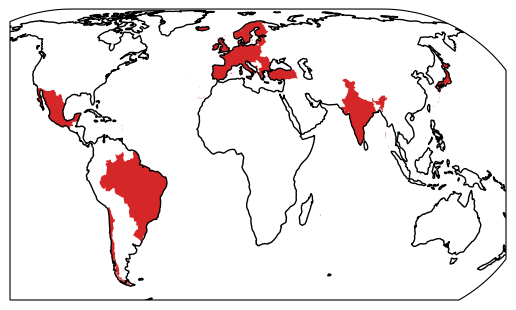

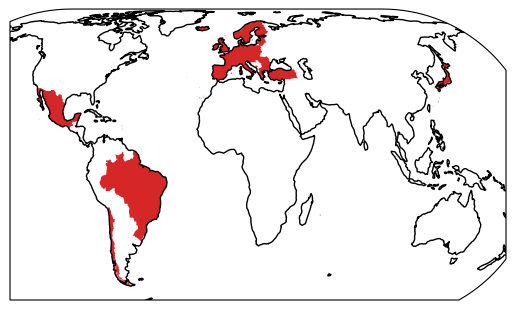

In [10]:
for typ in geoms:
    output_fn = f'{dir_list['figs']}extra_figs/insample_{typ}'
    fig = plt.figure()
    ax = plt.subplot(projection=ccrs.EckertIV())
    ax = gpd.GeoSeries(geoms[typ]).plot(fc='tab:red',ax=ax,transform=ccrs.PlateCarree())
    ax.coastlines()
    utility_print(output_fn)

## Map figures, for the full sample and all GWLs

/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/pyogrio/raw.py:200: RuntimeWarning: /glade/u/home/schwarzwald/projects/impact_uncertainty/aux_data/geo_data/impact-region.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/uncert_part_map_allprocs_allgwls.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/uncert_part_map_allprocs_allgwls.png saved!


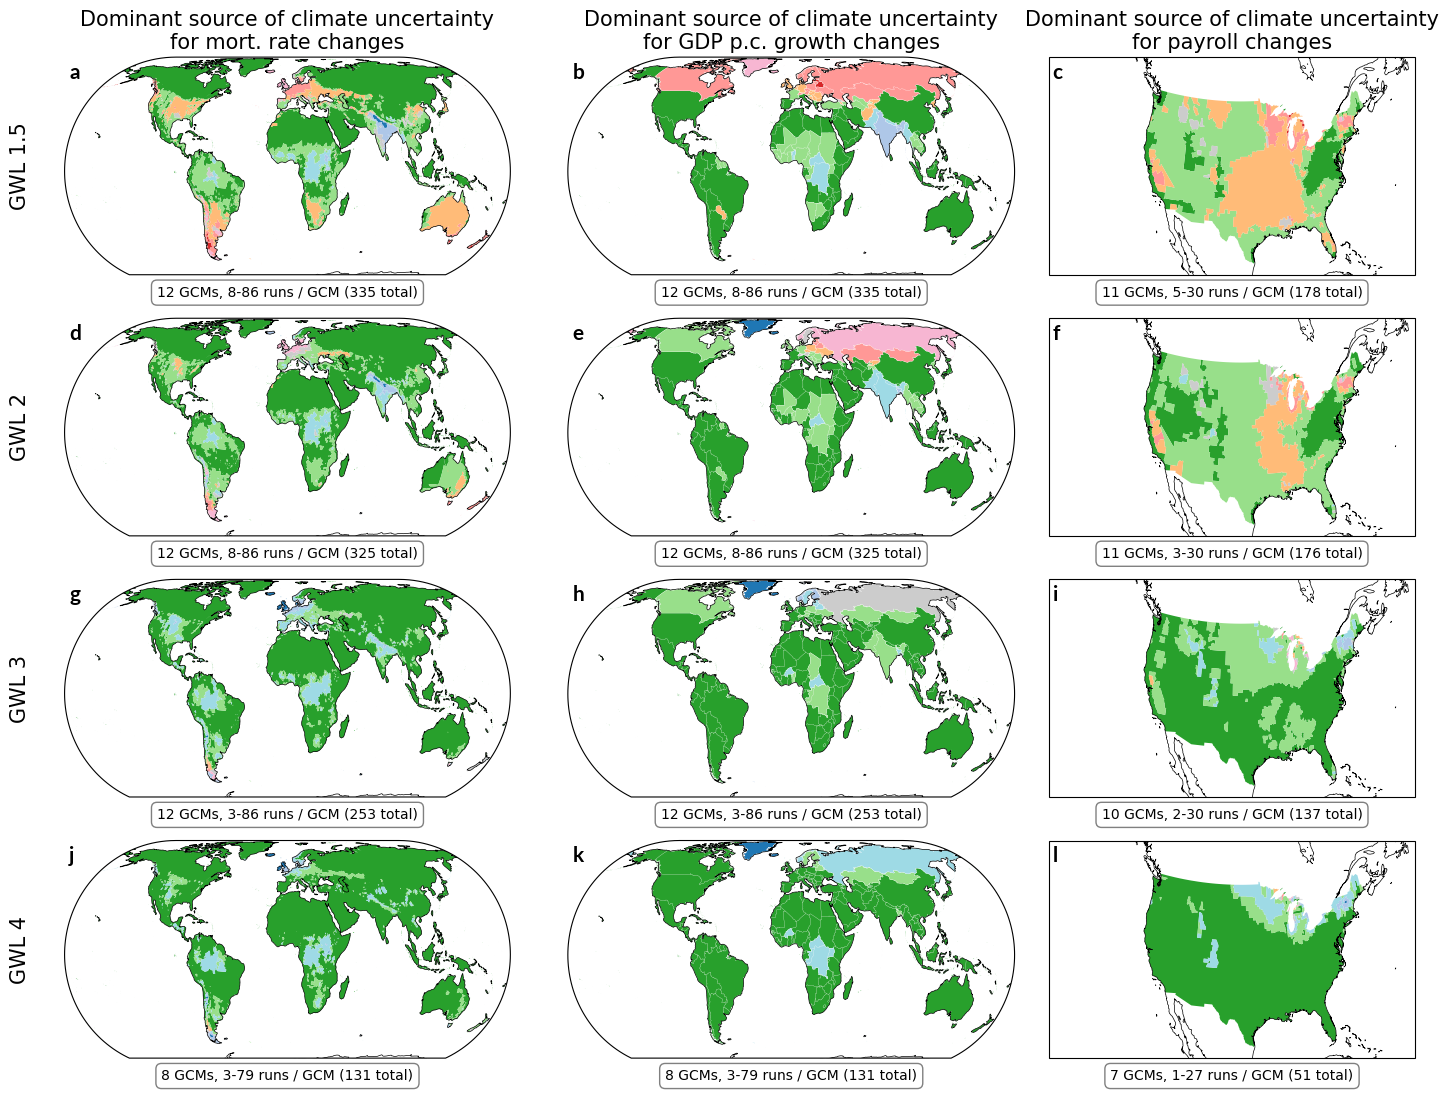

In [11]:
save_fig = True
output_fn = f'{dir_list['figs']}extra_figs/uncert_part_map_allprocs_allgwls'

imp_params = {'mortality':{'timeframe':'1980-2010','obstreat':'sep','resolution':'025deg','spec':'pooled','indflag':'noInd'},
              'gdppc':{'timeframe':'1980-2010','obstreat':'sep','resolution':'025deg'},
              'payroll':{'timeframe':'1986-2008','obstreat':'sep','resolution':'025deg','weighting':'pop'}}

uncert_typ = {proc:'allruns' for proc in imp_params}

plot_gwls = [1.5,2,3,4]

projs = {'mortality':ccrs.EckertIV(),
         'gdppc':ccrs.EckertIV(),
         'payroll':ccrs.AlbersEqualArea(central_longitude=-100,central_latitude=35)}



fig = plt.figure(figsize=(19.5,13))
gs = plt.GridSpec(nrows=len(plot_gwls),
                  ncols= 4*len(imp_params),
                  hspace = 0.2,wspace=0)

# Now, just the map
for col_idx,proc in enumerate(['mortality','gdppc','payroll']):
    #-------------------------
    # Load plot data ---------
    #-------------------------
    
    # Load partitioned uncertainty
    fn = f'{dir_list['proc']}uncert_parts/uncert_parts_{proc}.zarr'
    uncerts = xr.open_zarr(fn).load()
    uncerts = uncerts.set_index(poly_idx = 'locid').rename({'poly_idx':'locid'})

    # Select desired specification
    uncerts = uncerts.sel(imp_params[proc])

    # Load shapefile
    gdf = gpd.read_file(f'{dir_list['aux']}geo_data/{params_proc[proc]['shp_fn']}.shp')
    gdf['geometry'] = gdf.make_valid()
    
    
    if params_proc[proc]['geo_typ'] == 'impact-regions':
        # Remove Antarctica
        gdf = gdf.query('ISO != "ATA"')
    elif params_proc[proc]['geo_typ'] == 'adm1':
        gdf = gdf.query('CNTRY_NAME != "Antarctica"')
    elif params_proc[proc]['geo_typ'] == 'adm2-us':
        # Remove Alaska and Hawaii
        gdf = gdf.iloc[[sn not in ['Alaska','Hawaii'] for sn in gdf.STATE_NAME.values]]
    
    # Name merging dimension 'locid'
    gdf = gdf.rename(idxs[params_proc[proc]['geo_typ']],axis=1)

    # Load which GWLs the runs reach
    maxgwls = load_impacts(proc,'allruns',subplt_locs[proc],return_maxgwl=True).load()
    
    #-------------------------
    # Map panel --------------
    #-------------------------
    for row_idx,gwl in enumerate(plot_gwls):

        if params_proc[proc]['geo_typ'] == 'adm2-us':
            # Only use part of the horizontal grid spec for the smaller counties map
            ax_map = fig.add_subplot(gs[row_idx,(col_idx*4):(col_idx*4+3)],projection=projs[proc])
        else: 
            ax_map = fig.add_subplot(gs[row_idx,(col_idx*4):(col_idx*4+4)],projection=projs[proc])
       
        plot_data = (uncerts.
                     sel(typ='norm',gwl=gwl,sample=uncert_typ[proc]).
                     to_dataarray().to_dataset(name='relvar'))
        # Turn scenario, model, internal into color triangle colors
        plot_data['colors'] = xr.DataArray(data=vals_to_color_triangle(plot_data['relvar'],
                                                                    dim='variable',
                                                                    col_names = {'r':'uncint',
                                                                                 'g':'uncobs',
                                                                                 'b':'uncmod'}),
                                                dims=['locid'])
        
        # Add to geodataframe
        plot_data = pd.merge(gdf,
                          (plot_data[['colors','locid']].to_dataframe().reset_index()),
                          on='locid')
        
        # Dissolve into single polygons by color to reduce pdf file size
        plot_data = plot_data.dissolve(by='colors').reset_index()
        
        # Plot
        plot_data.plot(color=plot_data.colors,ax=ax_map,transform=ccrs.PlateCarree())
        # Plot national boundaries at least
        if proc == 'gdppc':
            gdf.plot(ax=ax_map,facecolor='none',edgecolor='w',linewidth=0.1,transform=ccrs.PlateCarree())

        # Make the payroll figure span a little wider, so the aspect ratio fits better
        # with the global maps
        if proc == 'payroll':
            ax_map.set_extent((-140, -64, 23.7, 50.6),
                      crs = ccrs.PlateCarree())
        # Annotations
        ax_map.coastlines(linewidth=0.5)
        ax_map.annotate(string.ascii_lowercase[row_idx*3+col_idx],(0.01,0.975),xycoords = 'axes fraction',
                    fontweight='bold',fontsize=15,va='top',font=extra_fonts['lato-bold'])

        # GWL on side
        if col_idx == 0:
            ax_map.annotate(f'GWL {str(gwl)}',(-0.1,0.5),
                            xycoords = 'axes fraction',
                            rotation=90,ha='center',va='center',
                            fontsize=15)

        # Title
        if row_idx == 0:
            ax_map.set_title('Dominant source of climate uncertainty\nfor '+proc_names[proc]+' changes',
                             fontsize=15)#font=extra_fonts['lato-bold'])

        # How many runs used
        nruns = uncerts.numruns.sel(sample=uncert_typ[proc],gwl=gwl).median('proj_base')
        nruns = nruns.where(nruns>0)
        nruns = nruns.dropna('model').astype(int)
        nruns_tot = nruns.sum('model').values
        nruns_str = f'{str(nruns.min('model').values)}-{str(nruns.max('model').values)} runs / GCM ({str(nruns_tot)} total)'
        
        desc_str = f'{str(nruns.sizes['model'])} GCMs, {nruns_str}'
        ax_map.annotate(desc_str,(0.5,-0.05),xycoords = 'axes fraction',va='top',ha='center',
                        bbox={'boxstyle':'round,pad=0.4','fc':'white','ec':'grey'})
    
if save_fig:
    utility_print(output_fn)



## Map figures, for the 1-degree results

/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/pyogrio/raw.py:200: RuntimeWarning: /glade/u/home/schwarzwald/projects/impact_uncertainty/aux_data/geo_data/impact-region.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/uncert_part_map_allprocs_1deg.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/uncert_part_map_allprocs_1deg.png saved!


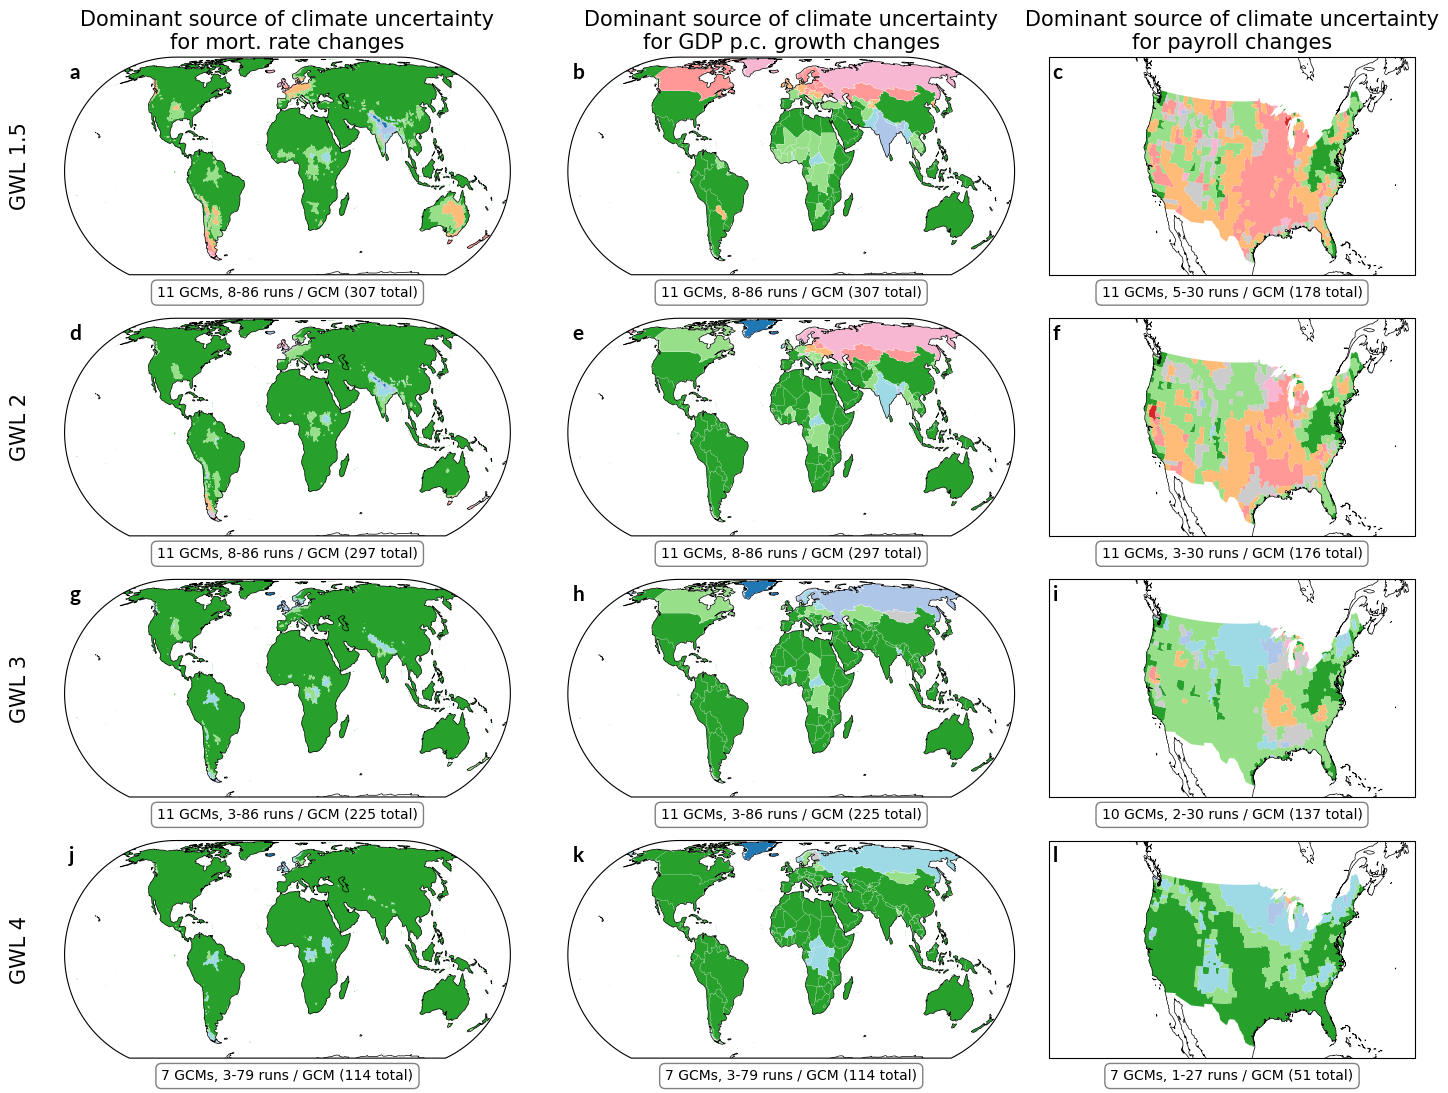

In [12]:
save_fig = True
output_fn = f'{dir_list['figs']}extra_figs/uncert_part_map_allprocs_1deg'

imp_params = {'mortality':{'timeframe':'1980-2010','obstreat':'sep','resolution':'1deg','spec':'pooled','indflag':'noInd'},
              'gdppc':{'timeframe':'1980-2010','obstreat':'sep','resolution':'1deg'},
              'payroll':{'timeframe':'1986-2008','obstreat':'sep','resolution':'1deg','weighting':'pop'}}

uncert_typ = {proc:'allruns' for proc in imp_params}

plot_gwls = [1.5,2,3,4]

projs = {'mortality':ccrs.EckertIV(),
         'gdppc':ccrs.EckertIV(),
         'payroll':ccrs.AlbersEqualArea(central_longitude=-100,central_latitude=35)}

fig = plt.figure(figsize=(19.5,13))
gs = plt.GridSpec(nrows=len(plot_gwls),
                  ncols= 4*len(imp_params),
                  hspace = 0.2,wspace=0)

# Now, just the map
for col_idx,proc in enumerate(['mortality','gdppc','payroll']):
    #-------------------------
    # Load plot data ---------
    #-------------------------
    
    # Load partitioned uncertainty
    fn = f'{dir_list['proc']}uncert_parts/uncert_parts_{proc}_1deg.zarr'
    uncerts = xr.open_zarr(fn).load()
    uncerts = uncerts.set_index(poly_idx = 'locid').rename({'poly_idx':'locid'})

    # Select desired specification
    uncerts = uncerts.sel(imp_params[proc])

    # Load shapefile
    gdf = gpd.read_file(f'{dir_list['aux']}geo_data/{params_proc[proc]['shp_fn']}.shp')
    gdf['geometry'] = gdf.make_valid()
    
    
    if params_proc[proc]['geo_typ'] == 'impact-regions':
        # Remove Antarctica
        gdf = gdf.query('ISO != "ATA"')
    elif params_proc[proc]['geo_typ'] == 'adm1':
        gdf = gdf.query('CNTRY_NAME != "Antarctica"')
    elif params_proc[proc]['geo_typ'] == 'adm2-us':
        # Remove Alaska and Hawaii
        gdf = gdf.iloc[[sn not in ['Alaska','Hawaii'] for sn in gdf.STATE_NAME.values]]
    
    # Name merging dimension 'locid'
    gdf = gdf.rename(idxs[params_proc[proc]['geo_typ']],axis=1)

    # Load which GWLs the runs reach
    maxgwls = load_impacts(proc,'allruns',subplt_locs[proc],return_maxgwl=True,
                           res='1deg').load()
    
    #-------------------------
    # Map panel --------------
    #-------------------------
    for row_idx,gwl in enumerate(plot_gwls):

        if params_proc[proc]['geo_typ'] == 'adm2-us':
            # Only use part of the horizontal grid spec for the smaller counties map
            ax_map = fig.add_subplot(gs[row_idx,(col_idx*4):(col_idx*4+3)],projection=projs[proc])
        else: 
            ax_map = fig.add_subplot(gs[row_idx,(col_idx*4):(col_idx*4+4)],projection=projs[proc])
       
        plot_data = (uncerts.
                     sel(typ='norm',gwl=gwl,sample=uncert_typ[proc]).
                     to_dataarray().to_dataset(name='relvar'))
        # Turn scenario, model, internal into color triangle colors
        plot_data['colors'] = xr.DataArray(data=vals_to_color_triangle(plot_data['relvar'],
                                                                    dim='variable',
                                                                    col_names = {'r':'uncint',
                                                                                 'g':'uncobs',
                                                                                 'b':'uncmod'}),
                                                dims=['locid'])
        
        # Add to geodataframe
        plot_data = pd.merge(gdf,
                          (plot_data[['colors','locid']].to_dataframe().reset_index()),
                          on='locid')
        
        # Dissolve into single polygons by color to reduce pdf file size
        plot_data = plot_data.dissolve(by='colors').reset_index()
        
        # Plot
        plot_data.plot(color=plot_data.colors,ax=ax_map,transform=ccrs.PlateCarree())
        # Plot national boundaries at least
        if proc == 'gdppc':
            gdf.plot(ax=ax_map,facecolor='none',edgecolor='w',linewidth=0.1,transform=ccrs.PlateCarree())

        # Make the payroll figure span a little wider, so the aspect ratio fits better
        # with the global maps
        if proc == 'payroll':
            ax_map.set_extent((-140, -64, 23.7, 50.6),
                      crs = ccrs.PlateCarree())
        
         # Annotations
        ax_map.coastlines(linewidth=0.5)
        ax_map.annotate(string.ascii_lowercase[row_idx*3+col_idx],(0.01,0.975),xycoords = 'axes fraction',
                    fontweight='bold',fontsize=15,va='top',font=extra_fonts['lato-bold'])

        # GWL on side
        if col_idx == 0:
            ax_map.annotate(f'GWL {str(gwl)}',(-0.1,0.5),
                            xycoords = 'axes fraction',
                            rotation=90,ha='center',va='center',
                            fontsize=15)

        # Title
        if row_idx == 0:
            ax_map.set_title('Dominant source of climate uncertainty\nfor '+proc_names[proc]+' changes',
                             fontsize=15)#font=extra_fonts['lato-bold'])

        # How many runs used
        nruns = uncerts.numruns.sel(sample=uncert_typ[proc],gwl=gwl).median('proj_base')
        nruns = nruns.where(nruns>0)
        nruns = nruns.dropna('model').astype(int)
        nruns_tot = nruns.sum('model').values
        nruns_str = f'{str(nruns.min('model').values)}-{str(nruns.max('model').values)} runs / GCM ({str(nruns_tot)} total)'
        
        desc_str = f'{str(nruns.sizes['model'])} GCMs, {nruns_str}'
        ax_map.annotate(desc_str,(0.5,-0.05),xycoords = 'axes fraction',va='top',ha='center',
                        bbox={'boxstyle':'round,pad=0.4','fc':'white','ec':'grey'})
    
if save_fig:
    utility_print(output_fn)



## Map figures, for the 1-degree, by-year results

/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/uncert_part_map_allprocs_1deg_alltimeframes.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/uncert_part_map_allprocs_1deg_alltimeframes.png saved!


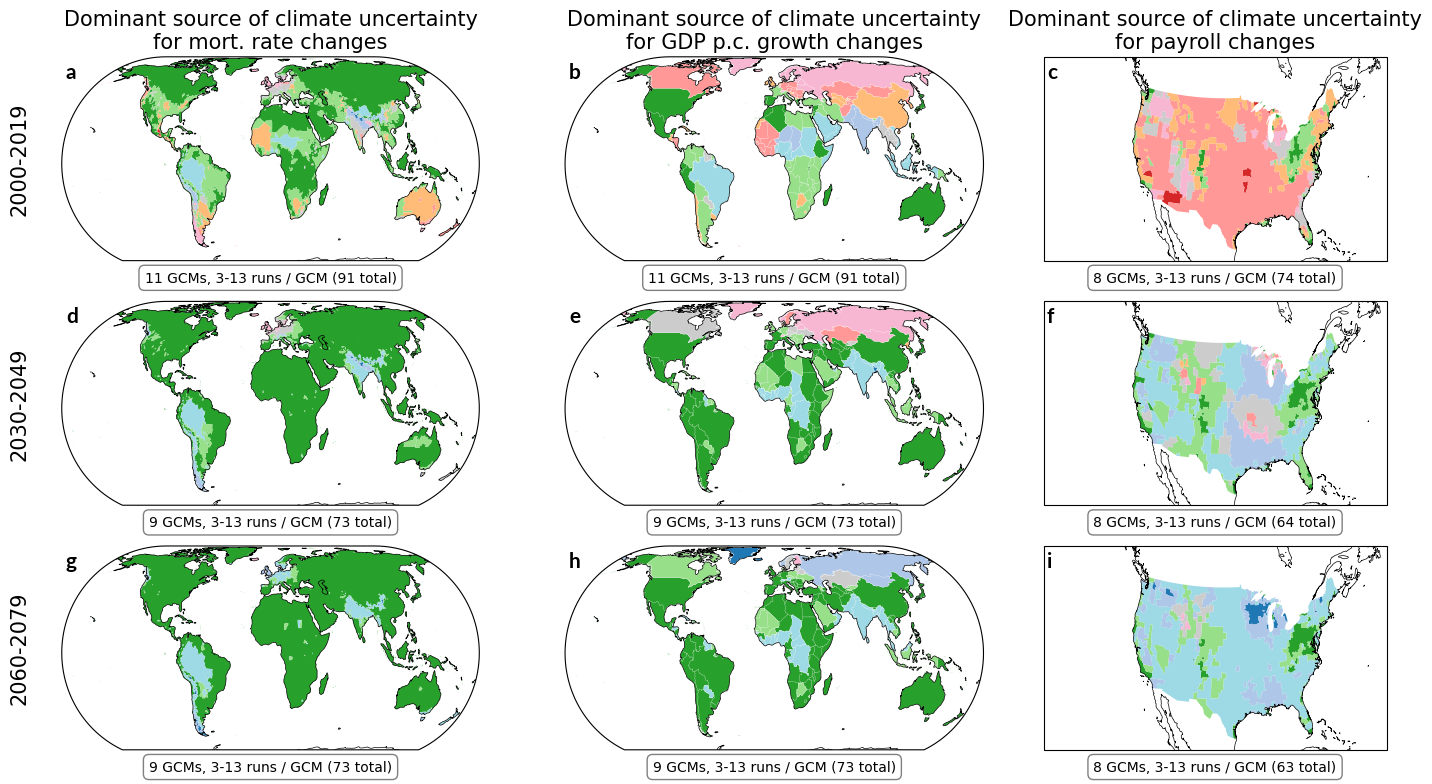

In [13]:
save_fig = True
output_fn = f'{dir_list['figs']}extra_figs/uncert_part_map_allprocs_1deg_alltimeframes'

imp_params = {'mortality':{'timeframe':'1980-2010','obstreat':'sep','resolution':'1deg','spec':'pooled','indflag':'noInd'},
              'gdppc':{'timeframe':'1980-2010','obstreat':'sep','resolution':'1deg'},
              'payroll':{'timeframe':'1986-2008','obstreat':'sep','resolution':'1deg','weighting':'pop'}}

uncert_typ = {proc:'atleast3runs' for proc in imp_params}

plot_gwls = [2010, 2040, 2070]

projs = {'mortality':ccrs.EckertIV(),
         'gdppc':ccrs.EckertIV(),
         'payroll':ccrs.AlbersEqualArea(central_longitude=-100,central_latitude=35)}

fig = plt.figure(figsize=(19.5,9))
gs = plt.GridSpec(nrows=len(plot_gwls),
                  ncols= 4*len(imp_params),
                  hspace = 0.2,wspace=0)

# Now, just the map
for col_idx,proc in enumerate(['mortality','gdppc','payroll']):
    #-------------------------
    # Load plot data ---------
    #-------------------------
    
    # Load partitioned uncertainty
    fn = f'{dir_list['proc']}uncert_parts/uncert_parts_{proc}_byyr.zarr'
    uncerts = xr.open_zarr(fn).load()
    uncerts = uncerts.set_index(poly_idx = 'locid').rename({'poly_idx':'locid'})

    # Select desired specification
    uncerts = uncerts.sel(imp_params[proc])

    # Load shapefile
    gdf = load_shp(proc)

    # Load which GWLs the runs reach
    maxgwls = load_impacts(proc,'allruns',subplt_locs[proc],return_maxgwl=True,res='1deg',byyr=True).load()
    
    #-------------------------
    # Map panel --------------
    #-------------------------
    for row_idx,gwl in enumerate(plot_gwls):

        if params_proc[proc]['geo_typ'] == 'adm2-us':
            # Only use part of the horizontal grid spec for the smaller counties map
            ax_map = fig.add_subplot(gs[row_idx,(col_idx*4):(col_idx*4+3)],projection=projs[proc])
        else: 
            ax_map = fig.add_subplot(gs[row_idx,(col_idx*4):(col_idx*4+4)],projection=projs[proc])
       
        plot_data = (uncerts.
                     sel(typ='norm',gwl=gwl,sample=uncert_typ[proc]).
                     to_dataarray().to_dataset(name='relvar'))
        # Turn scenario, model, internal into color triangle colors
        plot_data['colors'] = xr.DataArray(data=vals_to_color_triangle(plot_data['relvar'],
                                                                    dim='variable',
                                                                    col_names = {'r':'uncint',
                                                                                 'g':'uncobs',
                                                                                 'b':'uncmod'}),
                                                dims=['locid'])
        
        # Add to geodataframe
        plot_data = pd.merge(gdf,
                          (plot_data[['colors','locid']].to_dataframe().reset_index()),
                          on='locid')
        
        # Dissolve into single polygons by color to reduce pdf file size
        plot_data = plot_data.dissolve(by='colors').reset_index()
        
        # Plot
        plot_data.plot(color=plot_data.colors,ax=ax_map,transform=ccrs.PlateCarree())
        # Plot national boundaries at least
        if proc == 'gdppc':
            gdf.plot(ax=ax_map,facecolor='none',edgecolor='w',linewidth=0.1,transform=ccrs.PlateCarree())

        # Make the payroll figure span a little wider, so the aspect ratio fits better
        # with the global maps
        if proc == 'payroll':
            ax_map.set_extent((-140, -64, 23.7, 50.6),
                      crs = ccrs.PlateCarree())
        
        # Annotations
        ax_map.coastlines(linewidth=0.5)
        ax_map.annotate(string.ascii_lowercase[row_idx*3+col_idx],(0.01,0.975),xycoords = 'axes fraction',
                    fontweight='bold',fontsize=15,va='top',font=extra_fonts['lato-bold'])

        # GWL on side
        if col_idx == 0:
            ax_map.annotate(f'{str(gwl-10)}-{str(gwl+9)}',(-0.1,0.5),
                            xycoords = 'axes fraction',
                            rotation=90,ha='center',va='center',
                            fontsize=15)

        # Title
        if row_idx == 0:
            ax_map.set_title('Dominant source of climate uncertainty\nfor '+proc_names[proc]+' changes',
                             fontsize=15)#font=extra_fonts['lato-bold'])

        # How many runs used
        nruns = uncerts.numruns.sel(sample=uncert_typ[proc],gwl=gwl).median('proj_base')
        nruns = nruns.where(nruns>0)
        nruns = nruns.dropna('model').astype(int)
        nruns_tot = nruns.sum('model').values
        nruns_str = f'{str(nruns.min('model').values)}-{str(nruns.max('model').values)} runs / GCM ({str(nruns_tot)} total)'
        
        desc_str = f'{str(nruns.sizes['model'])} GCMs, {nruns_str}'
        ax_map.annotate(desc_str,(0.5,-0.05),xycoords = 'axes fraction',va='top',ha='center',
                        bbox={'boxstyle':'round,pad=0.4','fc':'white','ec':'grey'})
    
if save_fig:
    utility_print(output_fn)



## Figure of removing which reanalysis leads to largest decrease in uncobs

In [58]:
from funcs_support import nan_argmin_xr

proc = 'mortality'
gdf = load_shp(proc)

# Load 0.25 main spec uncertainties
fn = f'{dir_list['proc']}uncert_parts/uncert_parts_{proc}.zarr'
uncerts = xr.open_zarr(fn).load()
uncerts = uncerts.set_index(poly_idx = 'locid').rename({'poly_idx':'locid'})

# Figure out which specifications are leaving out one reanalysis
leave_one_out_samples = [sample for sample in uncerts.sample.values if re.search(r'\_no',sample) ]
parent_sample = np.unique([re.split(r'\_',sample)[0] for sample in leave_one_out_samples])[0]

# Calculate anomaly of variance across obs. between the leave one out and 
# all-obs uncertainty quantification
uncobs_anom = (uncerts.sel(sample = leave_one_out_samples).uncobs - 
               uncerts.sel(sample = parent_sample).uncobs)

In [59]:
# Get index of reanalysis with the largest decrease in uncertainty when left out
biggest_dec_obsmod = nan_argmin_xr(uncobs_anom,dim='sample')
biggest_dec_obsmod = biggest_dec_obsmod.dropna('locid',how='all').dropna('gwl',how='all').astype(int)#.dropna('locid',how='any').astype(int)
# Convert index to reanalysis name
biggest_dec_obsmod = xr.apply_ufunc(lambda x: re.split(r'\_no',x)[-1],
                uncobs_anom.sample.isel(sample=biggest_dec_obsmod),
               vectorize=True)

In [60]:
# Select desired specification
#uncobs_anom = uncobs_anom.sel(imp_params[proc]).sel(typ='raw')
#biggest_dec_obsmod_tmp = biggest_dec_obsmod.sel(timeframe='ALLYEARS',
#                                                obstreat = 'sep',
#                                                resolution = '025deg',
#                                                spec = 'pooled',
#                                                indflag = 'wInd').sel(typ='raw')


# Select desired specification
#uncobs_anom = uncobs_anom.sel(imp_params[proc]).sel(typ='raw')
biggest_dec_obsmod_tmp = biggest_dec_obsmod.sel(timeframe='ALLYEARS',
                                                obstreat = 'sep',
                                                resolution = '025deg',
                                                spec = 'pooled',
                                                indflag = 'noInd').sel(typ='raw')

(<Figure size 640x480 with 1 Axes>, <GeoAxes: >)

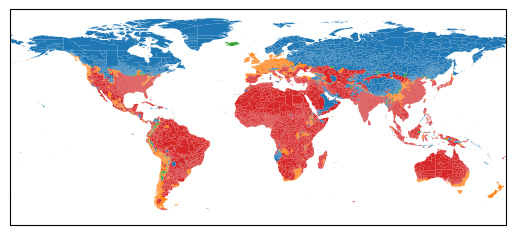

In [61]:
plot_map(biggest_dec_obsmod_tmp.sel(locid = gdf.locid.values).sel(gwl=2),
         gdf,
         cat_cmap = {'ERA5':'tab:red',
            'MERRA2':'tab:green',
            'JRA-3Q':'tab:orange',
            'GMFD':'tab:blue'})

(<Figure size 640x480 with 1 Axes>, <GeoAxes: >)

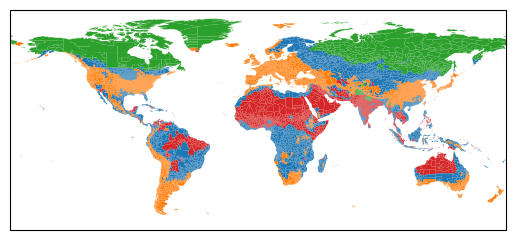

In [62]:
# Select desired specification
uncobs_anom = uncobs_anom.sel(imp_params[proc]).sel(typ='raw')
biggest_dec_obsmod_tmp = biggest_dec_obsmod.sel(timeframe='ALLYEARS',
                                                obstreat = 'sep',
                                                resolution = '025deg',
                                                spec = 'pooled',
                                                indflag = 'wInd').sel(typ='raw')

plot_map(biggest_dec_obsmod_tmp.sel(locid = gdf.locid.values).sel(gwl=2),
         gdf,
         cat_cmap = {'ERA5':'tab:red',
            'MERRA2':'tab:green',
            'JRA-3Q':'tab:orange',
            'GMFD':'tab:blue'})